# **Diabetes Prevalence in New Zealand EDA🔵**

**VDR** (Virtual Diabetes Register) is a tool used for tracking the number of people living with diabetes in New Zealand. This notebook used a dataset which has the VDR details taken in the year 2025. Diabetes is a medical condition where there is high blood sugar which makes the human body unable to produce insulin or use if effectively. There are different types of diabetes such as:
* Type 1 Diabetes
* Type 2 Diabetes
* Gestational Diabetes
* Prediabetes

# 📋**Table of Contents**
- [Importing libraries](#importing_libraries_section)
- [Loading dataset](#loading_dataset_section)
- [Initial Data Exploration](#initial_data_exploration_section)
- [Data cleaning](#data_cleaning_section)
- [Exporting cleaned datasets](#exporting_cleaned_datasets_section)
- [Data visualization](#data_visualization_section)
    - [Univariate analysis](#univariate_analysis_section)
    - [Bivariate analysis](#bivariate_analysis_section)
    - [Multivariate analysis](#multivariate_analysis_section)
- [Key insights](#key_insights_section)

# 📦**Importing Libraries**    <a class="anchor" id="importing_libraries_section"></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn
import plotly.express as px
import json
from urllib.request import urlopen
import plotly.io as pio
pio.renderers.default = "iframe"
import os

# 📂**Loading Dataset**     <a class="anchor" id="loading_dataset_section"></a>

In [2]:
os.makedirs("/kaggle/working/plots/",exist_ok=True)
diabetes_vdr_nz = pd.read_csv("/kaggle/input/datasets/reshmaharidhas/virtual-diabetes-register-vdr-of-new-zealand/diabetus_vdr_dataset.csv")
pd.set_option("display.max_columns",None)
diabetes_vdr_nz

,District,Maori,Pacific people,Indian,European/ Other,VDR total (age 15-74),VDR total (all ages),Percentage of people in the 15-74 age group
0,Auckland,"2,838","7,921","5,483","14,879","31,121","39,365",79.10%
1,Bay of Plenty,"4,161",434,743,"6,228","11,566","16,076",71.90%
2,Canterbury,"2,831","1,641","1,408","19,883","25,763","34,459",74.80%
3,Capital and Coast,"2,120","2,827","1,497","8,508","14,952","19,249",77.70%
4,Counties Manukau,"7,317","22,334","9,184","17,783","56,618","67,996",83.30%
5,Hawkes Bay,"3,378",688,358,"5,117","9,541","12,730",74.90%
6,Hutt,"1,815","1,550",831,"5,104","9,300","11,834",78.60%
7,Lakes,"3,034",328,268,"2,880","6,510","8,368",77.80%
8,MidCentral,"2,212",615,354,"6,311","9,492","12,771",74.30%
9,Nelson Marlborough,852,255,160,"4,694","5,961","8,526",69.90%


### 🎨Initializing Color palette

In [3]:
ethnicity_color_dict = {
    "maori":"#ef233c",
    "pacific_people":"#affc41",
    "indian":"gold",
    "european_or_others":"deepskyblue"
}
island_color_dict = {
    "North":"orangered",
    "South":"green",
    "Unknown":"grey"
}

# 🔍**Initial Data Exploration**   <a class="anchor" id="initial_data_exploration_section"></a>

In [4]:
diabetes_vdr_nz.shape

(21, 8)

In [5]:
diabetes_vdr_nz.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 8 columns):
 #   Column                                       Non-Null Count  Dtype 
---  ------                                       --------------  ----- 
 0   District                                     21 non-null     object
 1   Maori                                        21 non-null     object
 2   Pacific people                               21 non-null     object
 3   Indian                                       21 non-null     object
 4   European/ Other                              21 non-null     object
 5   VDR total (age 15-74)                        21 non-null     object
 6   VDR total (all ages)                         21 non-null     object
 7   Percentage of people in the 15-74 age group  21 non-null     object
dtypes: object(8)
memory usage: 1.4+ KB


In [6]:
diabetes_vdr_nz.describe()

,District,Maori,Pacific people,Indian,European/ Other,VDR total (age 15-74),VDR total (all ages),Percentage of people in the 15-74 age group
count,21,21,21,21,21,21,21,21
unique,21,21,21,21,21,21,21,21
top,Auckland,"2,838","7,921","5,483","14,879","31,121","39,365",79.10%
freq,1,1,1,1,1,1,1,1


### Duplicate check

In [7]:
diabetes_vdr_nz[diabetes_vdr_nz.duplicated]

,District,Maori,Pacific people,Indian,European/ Other,VDR total (age 15-74),VDR total (all ages),Percentage of people in the 15-74 age group


#### Observation
- There are no duplicate rows present in this dataset.

### **Count of missing data**

In [8]:
diabetes_vdr_nz.isna().sum()

District                                       0
Maori                                          0
Pacific people                                 0
Indian                                         0
European/ Other                                0
VDR total (age 15-74)                          0
VDR total (all ages)                           0
Percentage of people in the 15-74 age group    0
dtype: int64

#### Observation
- There are no NULL values in the dataset.

# 🧹**Data Cleaning**   <a class="anchor" id="data_cleaning_section"></a>

### **Standardizing column names**

In [9]:
diabetes_vdr_nz.columns = diabetes_vdr_nz.columns.str.strip().str.lower().str.replace(" ","_").str.replace("/","").str.replace("(","")
diabetes_vdr_nz.head()

,district,maori,pacific_people,indian,european_other,vdr_total_age_15-74),vdr_total_all_ages),percentage_of_people_in_the_15-74_age_group
0,Auckland,"2,838","7,921","5,483","14,879","31,121","39,365",79.10%
1,Bay of Plenty,"4,161",434,743,"6,228","11,566","16,076",71.90%
2,Canterbury,"2,831","1,641","1,408","19,883","25,763","34,459",74.80%
3,Capital and Coast,"2,120","2,827","1,497","8,508","14,952","19,249",77.70%
4,Counties Manukau,"7,317","22,334","9,184","17,783","56,618","67,996",83.30%


### **Renaming columns**

In [10]:
diabetes_vdr_nz = diabetes_vdr_nz.rename(columns={diabetes_vdr_nz.columns[4]:"european_or_others",diabetes_vdr_nz.columns[5]:"vdr_total_aged_15_to_74",diabetes_vdr_nz.columns[6]:"vdr_total_all_ages",diabetes_vdr_nz.columns[7]:"vdr_pct_aged_15_to_74"})
diabetes_vdr_nz.head()

,district,maori,pacific_people,indian,european_or_others,vdr_total_aged_15_to_74,vdr_total_all_ages,vdr_pct_aged_15_to_74
0,Auckland,"2,838","7,921","5,483","14,879","31,121","39,365",79.10%
1,Bay of Plenty,"4,161",434,743,"6,228","11,566","16,076",71.90%
2,Canterbury,"2,831","1,641","1,408","19,883","25,763","34,459",74.80%
3,Capital and Coast,"2,120","2,827","1,497","8,508","14,952","19,249",77.70%
4,Counties Manukau,"7,317","22,334","9,184","17,783","56,618","67,996",83.30%


### **Standardizing column data**

In [11]:
diabetes_vdr_nz["maori"] = diabetes_vdr_nz["maori"].str.strip().str.replace(",","")
diabetes_vdr_nz["pacific_people"] = diabetes_vdr_nz["pacific_people"].str.strip().str.replace(",","")
diabetes_vdr_nz["indian"] = diabetes_vdr_nz["indian"].str.strip().str.replace(",","")
diabetes_vdr_nz["european_or_others"] = diabetes_vdr_nz["european_or_others"].str.strip().str.replace(",","")
diabetes_vdr_nz["vdr_total_aged_15_to_74"] = diabetes_vdr_nz["vdr_total_aged_15_to_74"].str.strip().str.replace(",","")
diabetes_vdr_nz["vdr_total_all_ages"] = diabetes_vdr_nz["vdr_total_all_ages"].str.strip().str.replace(",","")
diabetes_vdr_nz["vdr_pct_aged_15_to_74"] = diabetes_vdr_nz["vdr_pct_aged_15_to_74"].str.strip().str.replace("%","")
diabetes_vdr_nz.head()

,district,maori,pacific_people,indian,european_or_others,vdr_total_aged_15_to_74,vdr_total_all_ages,vdr_pct_aged_15_to_74
0,Auckland,2838,7921,5483,14879,31121,39365,79.10
1,Bay of Plenty,4161,434,743,6228,11566,16076,71.90
2,Canterbury,2831,1641,1408,19883,25763,34459,74.80
3,Capital and Coast,2120,2827,1497,8508,14952,19249,77.70
4,Counties Manukau,7317,22334,9184,17783,56618,67996,83.30


### **Changing Datatype**

In [12]:
diabetes_vdr_nz["maori"] = diabetes_vdr_nz["maori"].astype(int)
diabetes_vdr_nz["pacific_people"] = diabetes_vdr_nz['pacific_people'].astype(int)
diabetes_vdr_nz['indian'] = diabetes_vdr_nz["indian"].astype(int)
diabetes_vdr_nz["european_or_others"] = diabetes_vdr_nz["european_or_others"].astype(int)
diabetes_vdr_nz["vdr_total_aged_15_to_74"] = diabetes_vdr_nz["vdr_total_aged_15_to_74"].astype(int)
diabetes_vdr_nz["vdr_total_all_ages"] = diabetes_vdr_nz["vdr_total_all_ages"].astype(int)
diabetes_vdr_nz["vdr_pct_aged_15_to_74"] = diabetes_vdr_nz["vdr_pct_aged_15_to_74"].astype(float)
diabetes_vdr_nz.head()

,district,maori,pacific_people,indian,european_or_others,vdr_total_aged_15_to_74,vdr_total_all_ages,vdr_pct_aged_15_to_74
0,Auckland,2838,7921,5483,14879,31121,39365,79.1
1,Bay of Plenty,4161,434,743,6228,11566,16076,71.9
2,Canterbury,2831,1641,1408,19883,25763,34459,74.8
3,Capital and Coast,2120,2827,1497,8508,14952,19249,77.7
4,Counties Manukau,7317,22334,9184,17783,56618,67996,83.3


In [13]:
diabetes_vdr_nz.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   district                 21 non-null     object 
 1   maori                    21 non-null     int64  
 2   pacific_people           21 non-null     int64  
 3   indian                   21 non-null     int64  
 4   european_or_others       21 non-null     int64  
 5   vdr_total_aged_15_to_74  21 non-null     int64  
 6   vdr_total_all_ages       21 non-null     int64  
 7   vdr_pct_aged_15_to_74    21 non-null     float64
dtypes: float64(1), int64(6), object(1)
memory usage: 1.4+ KB


In [14]:
north_districts = ['Auckland','Bay of Plenty','Counties Manukau','Hawkes Bay','Hutt','MidCentral','Northland','Tairawhiti','Taranaki','Waikato','Wairarapa','Waitemata','Whanganui']
diabetes_vdr_nz["island"] = diabetes_vdr_nz["district"].apply(lambda district:"North" if district in north_districts else("Unknown" if district=="Unknown/Unassigned" else("South")))
diabetes_vdr_nz.head(10)

,district,maori,pacific_people,indian,european_or_others,vdr_total_aged_15_to_74,vdr_total_all_ages,vdr_pct_aged_15_to_74,island
0,Auckland,2838,7921,5483,14879,31121,39365,79.1,North
1,Bay of Plenty,4161,434,743,6228,11566,16076,71.9,North
2,Canterbury,2831,1641,1408,19883,25763,34459,74.8,South
3,Capital and Coast,2120,2827,1497,8508,14952,19249,77.7,South
4,Counties Manukau,7317,22334,9184,17783,56618,67996,83.3,North
5,Hawkes Bay,3378,688,358,5117,9541,12730,74.9,North
6,Hutt,1815,1550,831,5104,9300,11834,78.6,North
7,Lakes,3034,328,268,2880,6510,8368,77.8,South
8,MidCentral,2212,615,354,6311,9492,12771,74.3,North
9,Nelson Marlborough,852,255,160,4694,5961,8526,69.9,South


In [15]:
diabetes_vdr_nz["island"].value_counts()

island
North      13
South       7
Unknown     1
Name: count, dtype: int64

In [16]:
diabetes_vdr_nz["most_dominant_eth_count"] = diabetes_vdr_nz[["maori","pacific_people","indian","european_or_others"]].max(axis=1)
diabetes_vdr_nz["least_dominant_eth_count"] = diabetes_vdr_nz[["maori","pacific_people","indian","european_or_others"]].min(axis=1)
diabetes_vdr_nz.head()

,district,maori,pacific_people,indian,european_or_others,vdr_total_aged_15_to_74,vdr_total_all_ages,vdr_pct_aged_15_to_74,island,most_dominant_eth_count,least_dominant_eth_count
0,Auckland,2838,7921,5483,14879,31121,39365,79.1,North,14879,2838
1,Bay of Plenty,4161,434,743,6228,11566,16076,71.9,North,6228,434
2,Canterbury,2831,1641,1408,19883,25763,34459,74.8,South,19883,1408
3,Capital and Coast,2120,2827,1497,8508,14952,19249,77.7,South,8508,1497
4,Counties Manukau,7317,22334,9184,17783,56618,67996,83.3,North,22334,7317


In [17]:
diabetes_vdr_nz["most_dominant_eth"]=diabetes_vdr_nz.apply(
    lambda vdr: "Maori"
    if vdr["most_dominant_eth_count"]==vdr["maori"]
    else(
        "Pacific"
        if vdr["most_dominant_eth_count"]==vdr["pacific_people"]
        else(
            "Indian"
            if vdr["most_dominant_eth_count"]==vdr["indian"]
            else "European/others")),axis=1,)
diabetes_vdr_nz

,district,maori,pacific_people,indian,european_or_others,vdr_total_aged_15_to_74,vdr_total_all_ages,vdr_pct_aged_15_to_74,island,most_dominant_eth_count,least_dominant_eth_count,most_dominant_eth
0,Auckland,2838,7921,5483,14879,31121,39365,79.1,North,14879,2838,European/others
1,Bay of Plenty,4161,434,743,6228,11566,16076,71.9,North,6228,434,European/others
2,Canterbury,2831,1641,1408,19883,25763,34459,74.8,South,19883,1408,European/others
3,Capital and Coast,2120,2827,1497,8508,14952,19249,77.7,South,8508,1497,European/others
4,Counties Manukau,7317,22334,9184,17783,56618,67996,83.3,North,22334,7317,Pacific
5,Hawkes Bay,3378,688,358,5117,9541,12730,74.9,North,5117,358,European/others
6,Hutt,1815,1550,831,5104,9300,11834,78.6,North,5104,831,European/others
7,Lakes,3034,328,268,2880,6510,8368,77.8,South,3034,268,Maori
8,MidCentral,2212,615,354,6311,9492,12771,74.3,North,6311,354,European/others
9,Nelson Marlborough,852,255,160,4694,5961,8526,69.9,South,4694,160,European/others


In [18]:
diabetes_vdr_nz["least_dominant_eth"]=diabetes_vdr_nz.apply(
    lambda vdr: "Maori"
    if vdr["least_dominant_eth_count"]==vdr["maori"]
    else(
        "Pacific"
        if vdr["least_dominant_eth_count"]==vdr["pacific_people"]
        else(
            "Indian"
            if vdr["least_dominant_eth_count"]==vdr["indian"]
            else "European/others")),axis=1,)
diabetes_vdr_nz

,district,maori,pacific_people,indian,european_or_others,vdr_total_aged_15_to_74,vdr_total_all_ages,vdr_pct_aged_15_to_74,island,most_dominant_eth_count,least_dominant_eth_count,most_dominant_eth,least_dominant_eth
0,Auckland,2838,7921,5483,14879,31121,39365,79.1,North,14879,2838,European/others,Maori
1,Bay of Plenty,4161,434,743,6228,11566,16076,71.9,North,6228,434,European/others,Pacific
2,Canterbury,2831,1641,1408,19883,25763,34459,74.8,South,19883,1408,European/others,Indian
3,Capital and Coast,2120,2827,1497,8508,14952,19249,77.7,South,8508,1497,European/others,Indian
4,Counties Manukau,7317,22334,9184,17783,56618,67996,83.3,North,22334,7317,Pacific,Maori
5,Hawkes Bay,3378,688,358,5117,9541,12730,74.9,North,5117,358,European/others,Indian
6,Hutt,1815,1550,831,5104,9300,11834,78.6,North,5104,831,European/others,Indian
7,Lakes,3034,328,268,2880,6510,8368,77.8,South,3034,268,Maori,Indian
8,MidCentral,2212,615,354,6311,9492,12771,74.3,North,6311,354,European/others,Indian
9,Nelson Marlborough,852,255,160,4694,5961,8526,69.9,South,4694,160,European/others,Indian


### **Changing column positions**

In [19]:
popped_most_dominant_eth = diabetes_vdr_nz.pop("most_dominant_eth")
diabetes_vdr_nz.insert(9,"most_dominant_eth",popped_most_dominant_eth)
diabetes_vdr_nz.head()

,district,maori,pacific_people,indian,european_or_others,vdr_total_aged_15_to_74,vdr_total_all_ages,vdr_pct_aged_15_to_74,island,most_dominant_eth,most_dominant_eth_count,least_dominant_eth_count,least_dominant_eth
0,Auckland,2838,7921,5483,14879,31121,39365,79.1,North,European/others,14879,2838,Maori
1,Bay of Plenty,4161,434,743,6228,11566,16076,71.9,North,European/others,6228,434,Pacific
2,Canterbury,2831,1641,1408,19883,25763,34459,74.8,South,European/others,19883,1408,Indian
3,Capital and Coast,2120,2827,1497,8508,14952,19249,77.7,South,European/others,8508,1497,Indian
4,Counties Manukau,7317,22334,9184,17783,56618,67996,83.3,North,Pacific,22334,7317,Maori


In [20]:
popped_least_dominant_eth = diabetes_vdr_nz.pop("least_dominant_eth")
diabetes_vdr_nz.insert(11,"least_dominant_eth",popped_least_dominant_eth)
diabetes_vdr_nz.head()

,district,maori,pacific_people,indian,european_or_others,vdr_total_aged_15_to_74,vdr_total_all_ages,vdr_pct_aged_15_to_74,island,most_dominant_eth,most_dominant_eth_count,least_dominant_eth,least_dominant_eth_count
0,Auckland,2838,7921,5483,14879,31121,39365,79.1,North,European/others,14879,Maori,2838
1,Bay of Plenty,4161,434,743,6228,11566,16076,71.9,North,European/others,6228,Pacific,434
2,Canterbury,2831,1641,1408,19883,25763,34459,74.8,South,European/others,19883,Indian,1408
3,Capital and Coast,2120,2827,1497,8508,14952,19249,77.7,South,European/others,8508,Indian,1497
4,Counties Manukau,7317,22334,9184,17783,56618,67996,83.3,North,Pacific,22334,Maori,7317


### **Checking inconsistencies in data**

In [21]:
diabetes_vdr_nz["most_dominant_eth"].value_counts()

most_dominant_eth
European/others    17
Maori               3
Pacific             1
Name: count, dtype: int64

In [22]:
diabetes_vdr_nz["least_dominant_eth"].value_counts()

least_dominant_eth
Indian     15
Maori       3
Pacific     3
Name: count, dtype: int64

In [23]:
diabetes_vdr_nz

,district,maori,pacific_people,indian,european_or_others,vdr_total_aged_15_to_74,vdr_total_all_ages,vdr_pct_aged_15_to_74,island,most_dominant_eth,most_dominant_eth_count,least_dominant_eth,least_dominant_eth_count
0,Auckland,2838,7921,5483,14879,31121,39365,79.1,North,European/others,14879,Maori,2838
1,Bay of Plenty,4161,434,743,6228,11566,16076,71.9,North,European/others,6228,Pacific,434
2,Canterbury,2831,1641,1408,19883,25763,34459,74.8,South,European/others,19883,Indian,1408
3,Capital and Coast,2120,2827,1497,8508,14952,19249,77.7,South,European/others,8508,Indian,1497
4,Counties Manukau,7317,22334,9184,17783,56618,67996,83.3,North,Pacific,22334,Maori,7317
5,Hawkes Bay,3378,688,358,5117,9541,12730,74.9,North,European/others,5117,Indian,358
6,Hutt,1815,1550,831,5104,9300,11834,78.6,North,European/others,5104,Indian,831
7,Lakes,3034,328,268,2880,6510,8368,77.8,South,Maori,3034,Indian,268
8,MidCentral,2212,615,354,6311,9492,12771,74.3,North,European/others,6311,Indian,354
9,Nelson Marlborough,852,255,160,4694,5961,8526,69.9,South,European/others,4694,Indian,160


### **Transposed dataset**

In [24]:
transposed_df = diabetes_vdr_nz.transpose()
transposed_df

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
district,Auckland,Bay of Plenty,Canterbury,Capital and Coast,Counties Manukau,Hawkes Bay,Hutt,Lakes,MidCentral,Nelson Marlborough,Northland,South Canterbury,Southern,Tairawhiti,Taranaki,Waikato,Wairarapa,Waitemata,West Coast,Whanganui,Unknown/Unassigned
maori,2838,4161,2831,2120,7317,3378,1815,3034,2212,852,5502,265,1722,1841,1677,7659,562,3751,209,1374,33
pacific_people,7921,434,1641,2827,22334,688,1550,328,615,255,353,121,814,143,161,1706,94,6101,39,167,20
indian,5483,743,1408,1497,9184,358,831,268,354,160,262,75,500,54,241,2123,80,4366,36,103,8
european_or_others,14879,6228,19883,8508,17783,5117,5104,2880,6311,4694,5119,2465,11952,867,4802,14676,1737,23370,1285,2242,43
vdr_total_aged_15_to_74,31121,11566,25763,14952,56618,9541,9300,6510,9492,5961,11236,2926,14988,2905,6881,26164,2473,37588,1569,3886,104
vdr_total_all_ages,39365,16076,34459,19249,67996,12730,11834,8368,12771,8526,14779,4143,20686,3794,9551,33923,3547,48578,2104,5222,133
vdr_pct_aged_15_to_74,79.1,71.9,74.8,77.7,83.3,74.9,78.6,77.8,74.3,69.9,76.0,70.6,72.5,76.6,72.0,77.1,69.7,77.4,74.6,74.4,78.2
island,North,North,South,South,North,North,North,South,North,South,North,South,South,North,North,North,North,North,South,North,Unknown
most_dominant_eth,European/others,European/others,European/others,European/others,Pacific,European/others,European/others,Maori,European/others,European/others,Maori,European/others,European/others,Maori,European/others,European/others,European/others,European/others,European/others,European/others,European/others


In [25]:
transposed_df.loc[["maori","pacific_people","indian","european_or_others"]]

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
maori,2838,4161,2831,2120,7317,3378,1815,3034,2212,852,5502,265,1722,1841,1677,7659,562,3751,209,1374,33
pacific_people,7921,434,1641,2827,22334,688,1550,328,615,255,353,121,814,143,161,1706,94,6101,39,167,20
indian,5483,743,1408,1497,9184,358,831,268,354,160,262,75,500,54,241,2123,80,4366,36,103,8
european_or_others,14879,6228,19883,8508,17783,5117,5104,2880,6311,4694,5119,2465,11952,867,4802,14676,1737,23370,1285,2242,43


### **Renaming column names in transposed dataset**

In [26]:
transposed_df.columns = transposed_df.iloc[0]
transposed_df

district,Auckland,Bay of Plenty,Canterbury,Capital and Coast,Counties Manukau,Hawkes Bay,Hutt,Lakes,MidCentral,Nelson Marlborough,Northland,South Canterbury,Southern,Tairawhiti,Taranaki,Waikato,Wairarapa,Waitemata,West Coast,Whanganui,Unknown/Unassigned
district,Auckland,Bay of Plenty,Canterbury,Capital and Coast,Counties Manukau,Hawkes Bay,Hutt,Lakes,MidCentral,Nelson Marlborough,Northland,South Canterbury,Southern,Tairawhiti,Taranaki,Waikato,Wairarapa,Waitemata,West Coast,Whanganui,Unknown/Unassigned
maori,2838,4161,2831,2120,7317,3378,1815,3034,2212,852,5502,265,1722,1841,1677,7659,562,3751,209,1374,33
pacific_people,7921,434,1641,2827,22334,688,1550,328,615,255,353,121,814,143,161,1706,94,6101,39,167,20
indian,5483,743,1408,1497,9184,358,831,268,354,160,262,75,500,54,241,2123,80,4366,36,103,8
european_or_others,14879,6228,19883,8508,17783,5117,5104,2880,6311,4694,5119,2465,11952,867,4802,14676,1737,23370,1285,2242,43
vdr_total_aged_15_to_74,31121,11566,25763,14952,56618,9541,9300,6510,9492,5961,11236,2926,14988,2905,6881,26164,2473,37588,1569,3886,104
vdr_total_all_ages,39365,16076,34459,19249,67996,12730,11834,8368,12771,8526,14779,4143,20686,3794,9551,33923,3547,48578,2104,5222,133
vdr_pct_aged_15_to_74,79.1,71.9,74.8,77.7,83.3,74.9,78.6,77.8,74.3,69.9,76.0,70.6,72.5,76.6,72.0,77.1,69.7,77.4,74.6,74.4,78.2
island,North,North,South,South,North,North,North,South,North,South,North,South,South,North,North,North,North,North,South,North,Unknown
most_dominant_eth,European/others,European/others,European/others,European/others,Pacific,European/others,European/others,Maori,European/others,European/others,Maori,European/others,European/others,Maori,European/others,European/others,European/others,European/others,European/others,European/others,European/others


In [27]:
district_names = transposed_df.columns

### **Standardizing column names**

In [28]:
transposed_df.columns = transposed_df.columns.str.strip().str.lower().str.replace(" ","_")
transposed_df

district,auckland,bay_of_plenty,canterbury,capital_and_coast,counties_manukau,hawkes_bay,hutt,lakes,midcentral,nelson_marlborough,northland,south_canterbury,southern,tairawhiti,taranaki,waikato,wairarapa,waitemata,west_coast,whanganui,unknown/unassigned
district,Auckland,Bay of Plenty,Canterbury,Capital and Coast,Counties Manukau,Hawkes Bay,Hutt,Lakes,MidCentral,Nelson Marlborough,Northland,South Canterbury,Southern,Tairawhiti,Taranaki,Waikato,Wairarapa,Waitemata,West Coast,Whanganui,Unknown/Unassigned
maori,2838,4161,2831,2120,7317,3378,1815,3034,2212,852,5502,265,1722,1841,1677,7659,562,3751,209,1374,33
pacific_people,7921,434,1641,2827,22334,688,1550,328,615,255,353,121,814,143,161,1706,94,6101,39,167,20
indian,5483,743,1408,1497,9184,358,831,268,354,160,262,75,500,54,241,2123,80,4366,36,103,8
european_or_others,14879,6228,19883,8508,17783,5117,5104,2880,6311,4694,5119,2465,11952,867,4802,14676,1737,23370,1285,2242,43
vdr_total_aged_15_to_74,31121,11566,25763,14952,56618,9541,9300,6510,9492,5961,11236,2926,14988,2905,6881,26164,2473,37588,1569,3886,104
vdr_total_all_ages,39365,16076,34459,19249,67996,12730,11834,8368,12771,8526,14779,4143,20686,3794,9551,33923,3547,48578,2104,5222,133
vdr_pct_aged_15_to_74,79.1,71.9,74.8,77.7,83.3,74.9,78.6,77.8,74.3,69.9,76.0,70.6,72.5,76.6,72.0,77.1,69.7,77.4,74.6,74.4,78.2
island,North,North,South,South,North,North,North,South,North,South,North,South,South,North,North,North,North,North,South,North,Unknown
most_dominant_eth,European/others,European/others,European/others,European/others,Pacific,European/others,European/others,Maori,European/others,European/others,Maori,European/others,European/others,Maori,European/others,European/others,European/others,European/others,European/others,European/others,European/others


### **Dropping irrelevant of transposed dataset**

In [29]:
transposed_df.drop("district",axis=0,inplace=True)
transposed_df


district,auckland,bay_of_plenty,canterbury,capital_and_coast,counties_manukau,hawkes_bay,hutt,lakes,midcentral,nelson_marlborough,northland,south_canterbury,southern,tairawhiti,taranaki,waikato,wairarapa,waitemata,west_coast,whanganui,unknown/unassigned
maori,2838,4161,2831,2120,7317,3378,1815,3034,2212,852,5502,265,1722,1841,1677,7659,562,3751,209,1374,33
pacific_people,7921,434,1641,2827,22334,688,1550,328,615,255,353,121,814,143,161,1706,94,6101,39,167,20
indian,5483,743,1408,1497,9184,358,831,268,354,160,262,75,500,54,241,2123,80,4366,36,103,8
european_or_others,14879,6228,19883,8508,17783,5117,5104,2880,6311,4694,5119,2465,11952,867,4802,14676,1737,23370,1285,2242,43
vdr_total_aged_15_to_74,31121,11566,25763,14952,56618,9541,9300,6510,9492,5961,11236,2926,14988,2905,6881,26164,2473,37588,1569,3886,104
vdr_total_all_ages,39365,16076,34459,19249,67996,12730,11834,8368,12771,8526,14779,4143,20686,3794,9551,33923,3547,48578,2104,5222,133
vdr_pct_aged_15_to_74,79.1,71.9,74.8,77.7,83.3,74.9,78.6,77.8,74.3,69.9,76.0,70.6,72.5,76.6,72.0,77.1,69.7,77.4,74.6,74.4,78.2
island,North,North,South,South,North,North,North,South,North,South,North,South,South,North,North,North,North,North,South,North,Unknown
most_dominant_eth,European/others,European/others,European/others,European/others,Pacific,European/others,European/others,Maori,European/others,European/others,Maori,European/others,European/others,Maori,European/others,European/others,European/others,European/others,European/others,European/others,European/others
most_dominant_eth_count,14879,6228,19883,8508,22334,5117,5104,3034,6311,4694,5502,2465,11952,1841,4802,14676,1737,23370,1285,2242,43


#### Observation:
- The first row of the dataframe 'transposed_df' had the same data as in the renamed column names in it. Hence, deleting that first row as an irrelevant row.

### **Resetting index of the transposed dataset**

In [30]:
diabetes_ethnicities_vdr_nz = transposed_df.reset_index()
diabetes_ethnicities_vdr_nz

district,index,auckland,bay_of_plenty,canterbury,capital_and_coast,counties_manukau,hawkes_bay,hutt,lakes,midcentral,nelson_marlborough,northland,south_canterbury,southern,tairawhiti,taranaki,waikato,wairarapa,waitemata,west_coast,whanganui,unknown/unassigned
0,maori,2838,4161,2831,2120,7317,3378,1815,3034,2212,852,5502,265,1722,1841,1677,7659,562,3751,209,1374,33
1,pacific_people,7921,434,1641,2827,22334,688,1550,328,615,255,353,121,814,143,161,1706,94,6101,39,167,20
2,indian,5483,743,1408,1497,9184,358,831,268,354,160,262,75,500,54,241,2123,80,4366,36,103,8
3,european_or_others,14879,6228,19883,8508,17783,5117,5104,2880,6311,4694,5119,2465,11952,867,4802,14676,1737,23370,1285,2242,43
4,vdr_total_aged_15_to_74,31121,11566,25763,14952,56618,9541,9300,6510,9492,5961,11236,2926,14988,2905,6881,26164,2473,37588,1569,3886,104
5,vdr_total_all_ages,39365,16076,34459,19249,67996,12730,11834,8368,12771,8526,14779,4143,20686,3794,9551,33923,3547,48578,2104,5222,133
6,vdr_pct_aged_15_to_74,79.1,71.9,74.8,77.7,83.3,74.9,78.6,77.8,74.3,69.9,76.0,70.6,72.5,76.6,72.0,77.1,69.7,77.4,74.6,74.4,78.2
7,island,North,North,South,South,North,North,North,South,North,South,North,South,South,North,North,North,North,North,South,North,Unknown
8,most_dominant_eth,European/others,European/others,European/others,European/others,Pacific,European/others,European/others,Maori,European/others,European/others,Maori,European/others,European/others,Maori,European/others,European/others,European/others,European/others,European/others,European/others,European/others
9,most_dominant_eth_count,14879,6228,19883,8508,22334,5117,5104,3034,6311,4694,5502,2465,11952,1841,4802,14676,1737,23370,1285,2242,43


In [31]:
diabetes_ethnicities_vdr_nz = diabetes_ethnicities_vdr_nz.loc[[0,1,2,3]]
diabetes_ethnicities_vdr_nz

district,index,auckland,bay_of_plenty,canterbury,capital_and_coast,counties_manukau,hawkes_bay,hutt,lakes,midcentral,nelson_marlborough,northland,south_canterbury,southern,tairawhiti,taranaki,waikato,wairarapa,waitemata,west_coast,whanganui,unknown/unassigned
0,maori,2838,4161,2831,2120,7317,3378,1815,3034,2212,852,5502,265,1722,1841,1677,7659,562,3751,209,1374,33
1,pacific_people,7921,434,1641,2827,22334,688,1550,328,615,255,353,121,814,143,161,1706,94,6101,39,167,20
2,indian,5483,743,1408,1497,9184,358,831,268,354,160,262,75,500,54,241,2123,80,4366,36,103,8
3,european_or_others,14879,6228,19883,8508,17783,5117,5104,2880,6311,4694,5119,2465,11952,867,4802,14676,1737,23370,1285,2242,43


### **Cleaned datasets**

In [32]:
diabetes_vdr_nz

,district,maori,pacific_people,indian,european_or_others,vdr_total_aged_15_to_74,vdr_total_all_ages,vdr_pct_aged_15_to_74,island,most_dominant_eth,most_dominant_eth_count,least_dominant_eth,least_dominant_eth_count
0,Auckland,2838,7921,5483,14879,31121,39365,79.1,North,European/others,14879,Maori,2838
1,Bay of Plenty,4161,434,743,6228,11566,16076,71.9,North,European/others,6228,Pacific,434
2,Canterbury,2831,1641,1408,19883,25763,34459,74.8,South,European/others,19883,Indian,1408
3,Capital and Coast,2120,2827,1497,8508,14952,19249,77.7,South,European/others,8508,Indian,1497
4,Counties Manukau,7317,22334,9184,17783,56618,67996,83.3,North,Pacific,22334,Maori,7317
5,Hawkes Bay,3378,688,358,5117,9541,12730,74.9,North,European/others,5117,Indian,358
6,Hutt,1815,1550,831,5104,9300,11834,78.6,North,European/others,5104,Indian,831
7,Lakes,3034,328,268,2880,6510,8368,77.8,South,Maori,3034,Indian,268
8,MidCentral,2212,615,354,6311,9492,12771,74.3,North,European/others,6311,Indian,354
9,Nelson Marlborough,852,255,160,4694,5961,8526,69.9,South,European/others,4694,Indian,160


In [33]:
diabetes_ethnicities_vdr_nz

district,index,auckland,bay_of_plenty,canterbury,capital_and_coast,counties_manukau,hawkes_bay,hutt,lakes,midcentral,nelson_marlborough,northland,south_canterbury,southern,tairawhiti,taranaki,waikato,wairarapa,waitemata,west_coast,whanganui,unknown/unassigned
0,maori,2838,4161,2831,2120,7317,3378,1815,3034,2212,852,5502,265,1722,1841,1677,7659,562,3751,209,1374,33
1,pacific_people,7921,434,1641,2827,22334,688,1550,328,615,255,353,121,814,143,161,1706,94,6101,39,167,20
2,indian,5483,743,1408,1497,9184,358,831,268,354,160,262,75,500,54,241,2123,80,4366,36,103,8
3,european_or_others,14879,6228,19883,8508,17783,5117,5104,2880,6311,4694,5119,2465,11952,867,4802,14676,1737,23370,1285,2242,43


# 💾**Exporting cleaned datasets**    <a class="anchor" id="exporting_cleaned_datasets_section"></a>

In [34]:
diabetes_vdr_nz.to_csv("cleaned_diabetes_vdr_nz.csv")

In [35]:
diabetes_ethnicities_vdr_nz.to_csv("cleaned_diabetes_ethnicities_vdr_nz.csv")

# 📊**Data Visualization**    <a class="anchor" id="data_visualization_section"></a>

## 📈**Univariate Analysis**    <a class="anchor" id="univariate_analysis_section"></a>

#### **Count of districts in islands of New Zealand with registered diabetes cases**

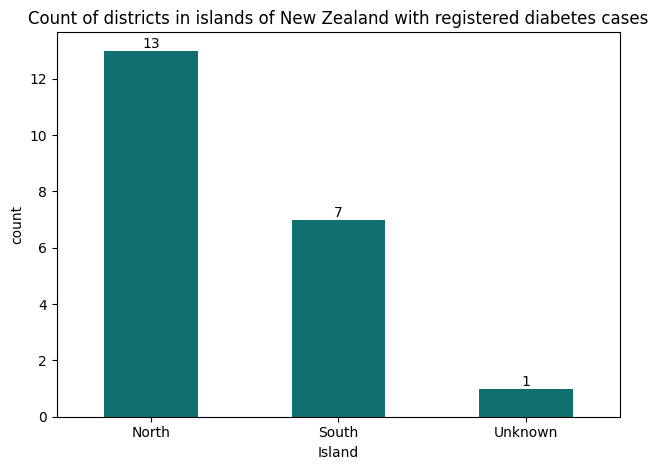

In [36]:
ax = seaborn.countplot(diabetes_vdr_nz,x="island",color="teal",width=0.5)
ax.bar_label(ax.containers[0])
plt.xlabel("Island")
plt.title("Count of districts in islands of New Zealand with registered diabetes cases")
plt.tight_layout()
plt.savefig("/kaggle/working/plots/count_of_districts_in_islands_of_nz_with_registered_diabetes_cases.png")

#### 💡Insights
- The number of people with diabetes in the districts of North island are more than in the South island.

#### **Percentage of people with diabetes cases by island type**

In [37]:
fig=px.pie(diabetes_vdr_nz,
           names="island",
           values="vdr_total_all_ages",
           title="Percentage of people with diabetes cases by island type",
           color_discrete_sequence=list(island_color_dict.values()),
           labels={"vdr_total_all_ages":"Total people with diabetes in all ages","island":"Island"})
fig.update_layout(title_x=0.5,title_font_color="black")
fig.update_traces(textinfo='label+percent')
fig.show()

#### **Comparison of ethnicities with highest & lowest cases of diabetes across districts of NZ**

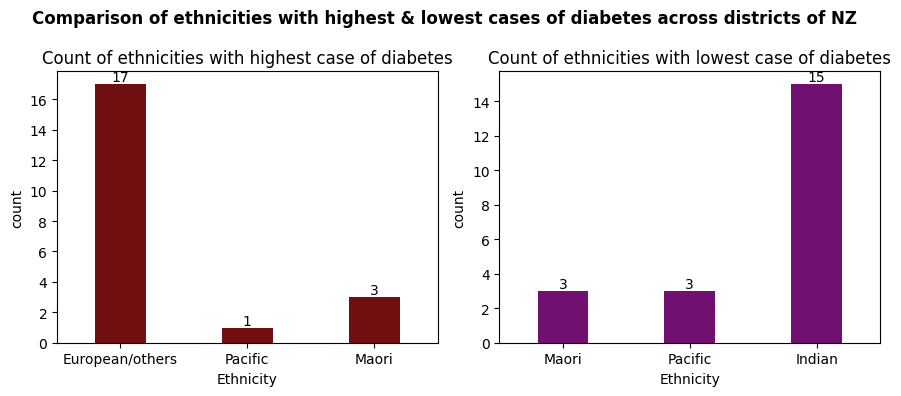

In [38]:
f,ax = plt.subplots(1,2,figsize=(9,4))
seaborn.countplot(diabetes_vdr_nz,x="most_dominant_eth",width=0.4,ax=ax[0],color="maroon")
seaborn.countplot(diabetes_vdr_nz,x="least_dominant_eth",width=0.4,ax=ax[1],color="purple")
ax[0].set_title("Count of ethnicities with highest case of diabetes")
ax[1].set_title("Count of ethnicities with lowest case of diabetes")
ax[0].set_xlabel("Ethnicity")
ax[1].set_xlabel("Ethnicity")
ax[0].bar_label(ax[0].containers[0])
ax[1].bar_label(ax[1].containers[0])
plt.suptitle("Comparison of ethnicities with highest & lowest cases of diabetes across districts of NZ",fontweight="bold")
plt.tight_layout()
plt.savefig("/kaggle/working/plots/comparison_of_ethnicities_with_highest_and_lowest_cases_of_diabetes_across_districts_of_nz.png")

#### 💡Insights
- Diabetes is highly prevalent among the European or other ethnic people in most of the districts in New Zealand.
- In 17 districts, European or other ethnic people have higher cases of diabetes.
- Maori people have higher cases of diabetes only in 3 districts of New Zealand.
- The ethnic group with less number of people with diabetes in New Zealand are Indians which amounts to 15 districts.

#### **Proportion of people with diabetes in New Zealand by districts & ethnicity**

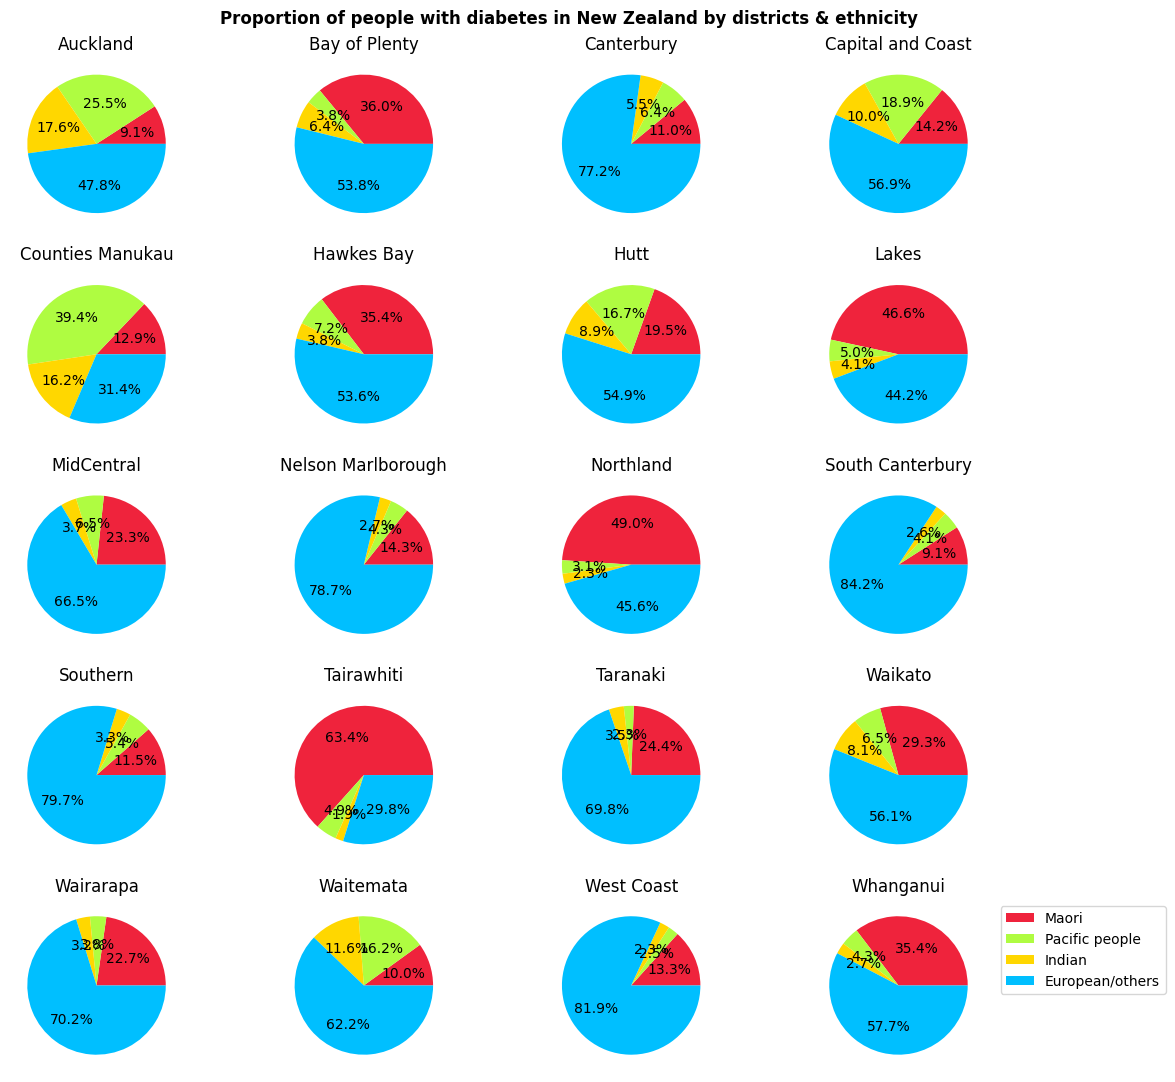

In [39]:
f,ax=plt.subplots(5,4,figsize=(13,11))
district_num_index = 1
for rowIndex in range(5):
  for colIndex in range(4):
    ax[rowIndex,colIndex].pie(diabetes_ethnicities_vdr_nz[diabetes_ethnicities_vdr_nz.columns[district_num_index]],labels=diabetes_ethnicities_vdr_nz["index"],autopct="%1.1f%%",labeldistance=None,colors=["#ef233c","#affc41","gold","deepskyblue"])
    ax[rowIndex,colIndex].set_title(district_names[district_num_index-1])
    district_num_index += 1
plt.suptitle("Proportion of people with diabetes in New Zealand by districts & ethnicity",fontweight="bold")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left',labels=["Maori", "Pacific people","Indian","European/others"])
plt.tight_layout()
plt.savefig("/kaggle/working/plots/proportion_of_people_with_diabetes_in_nz_by_districts_and_ethnicity.png")

#### 💡Insights
- The European or other ethnic people in most of the districts of New Zealand have higher cases of diabetes.
- 84.2% and 79% of European or other ethnic people living in Canterbury and Southern district have higher cases of diabetes.
- The diabetes cases in Nelson Marlborough are higher among the European or other ethnic peoples.
- Maori people in Tairawhiti have highest cases of diabetes which accounts to 63.4% among all ethnic groups.
- Maori people in Auckland and Waitemata have lower cases of diabetes.
- Pacific people in Counties Manukau have higher percentage of diabetic cases among all the other districts which accounts to 39.4%
- Less than 20% of indians have diabetes in all the districts of New Zealand making Indians the least dominant ethnic group with diabetes.

## 📈**Bivariate Analysis**     <a class="anchor" id="bivariate_analysis_section"></a>

#### **Number of people with diabetes in NZ by island**

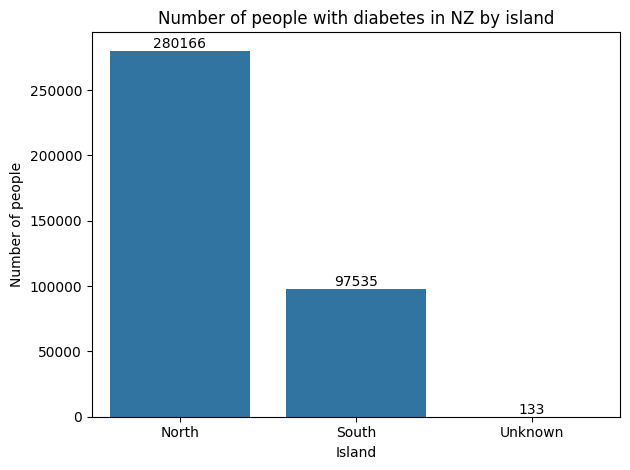

In [40]:
ax=seaborn.barplot(diabetes_vdr_nz,x="island",y="vdr_total_all_ages",estimator="sum",errorbar=None)
ax.bar_label(ax.containers[0])
plt.xlabel("Island")
plt.ylabel("Number of people")
plt.title("Number of people with diabetes in NZ by island")
plt.tight_layout()
plt.savefig("/kaggle/working/plots/number_of_people_with_diabetes_in_nz_by_island.png")

#### 💡Insights
- 280166 people living in the North island of New Zealand have diabetes.
- The number of people with diabetes in the North island is more than the people with diabetes in the South island of New Zealand.

#### **Number of people with diabetes in NZ in all ages by district**

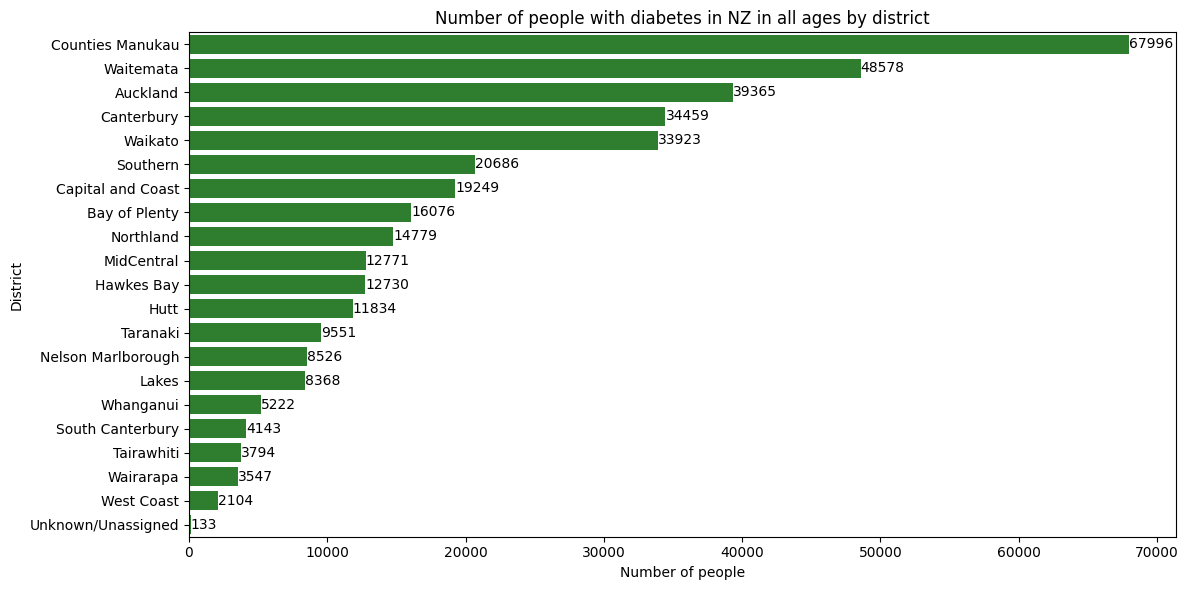

In [41]:
plt.figure(figsize=(12,6))
ax=seaborn.barplot(diabetes_vdr_nz.sort_values(by=["vdr_total_all_ages"],ascending=False),y="district",x="vdr_total_all_ages",color="forestgreen")
ax.bar_label(ax.containers[0])
plt.xlabel("Number of people")
plt.ylabel("District")
plt.title("Number of people with diabetes in NZ in all ages by district")
plt.tight_layout()
plt.savefig("/kaggle/working/plots/number_of_people_with_diabetes_in_nz_in_all_ages_by_district.png")

#### **Number of people with diabetes of all ages in New Zealand by island & districts**

In [42]:
fig=px.treemap(data_frame=diabetes_vdr_nz,path=["island","district"],values="vdr_total_all_ages",title="Number of people with diabetes of all ages in New Zealand by island & districts",labels={"vdr_total_all_ages":"Total number of people with diabetes in all ages","island":"Island","district":"District"},color_discrete_sequence=list(island_color_dict.values()))
fig.update_layout(title_x=0.5,title_font_color="black")
fig.update_traces(textinfo="label+value")
fig.show()

#### 💡Insights
- Counties Manukau has the highest number of people with diabetes in the North island of New Zealand.
- Waitemata ranks second in the highest number of people with diabetes in the North island followed by Auckland with 39365 people.
- Canterbury ranks first among the South island districts with highest number of diabetes in New Zealand.
- West Coast district of South island has less number of people with diabetes which is exactly 2104 people.

#### **Top 5 North island districts with highest cases of diabetes**

In [43]:
total_people_in_north_island_vdr = diabetes_vdr_nz[diabetes_vdr_nz["island"]=="North"].sort_values(by=["vdr_total_all_ages"],ascending=False)
fig=px.bar(total_people_in_north_island_vdr.head(5),x="district",y="vdr_total_all_ages",width=900,title="Top 5 North island districts with highest cases of diabetes",text_auto=True,color_discrete_sequence=[island_color_dict["North"]],labels={"vdr_total_all_ages":"Total people with diabetes in all ages"})
fig.update_layout(title_x=0.5,title_font_color="black",xaxis_title="District",yaxis_title="Number of people")
fig.update_yaxes(tickformat=",d")
fig.show()

#### **Top 5 South island districts with highest cases of diabetes**

In [44]:
total_people_in_south_island_vdr = diabetes_vdr_nz[diabetes_vdr_nz["island"]=="South"].sort_values(by=["vdr_total_all_ages"],ascending=False)
fig=px.bar(total_people_in_south_island_vdr.head(),x="district",y="vdr_total_all_ages",
           title="Top 5 South island districts with highest cases of diabetes",
           width=800,
           text_auto=True,
           color_discrete_sequence=[island_color_dict["South"]],
           labels={"vdr_total_all_ages":"Total people in all ages"})
fig.update_layout(title_x=0.5,title_font_color="black",xaxis_title="District",yaxis_title="Number of people")
fig.update_yaxes(tickformat=",d")
fig.show()

#### **Number of Pacific ethnic people with diabetes in New Zealand by districts**

In [45]:
fig=px.bar(diabetes_vdr_nz.sort_values(by=["pacific_people"],ascending=False),x="district",y="pacific_people",title="Number of Pacific ethnic people with diabetes in New Zealand by districts",color_discrete_sequence=[ethnicity_color_dict["pacific_people"]],text_auto=True,labels={"pacific_people":"Number of pacific people","district":"District"})
fig.update_layout(title_x=0.5,title_font_color="black")
fig.update_yaxes(tickformat=",d")
fig.show()

#### 💡Insights
- West Coast and Wairarapa have less than 100 Pacific ethnic people with diabetes.

#### **Number of Maori people with diabetes in New Zealand by districts**

In [46]:
fig=px.bar(diabetes_vdr_nz.sort_values(by=["maori"],ascending=False),x="district",y="maori",title="Number of Maori people with diabetes in New Zealand by districts",color_discrete_sequence=[ethnicity_color_dict["maori"]],text_auto=True,labels={"maori":"Number of Maori people","district":"District"})
fig.update_layout(title_x=0.5,title_font_color="black")
fig.show()

#### 💡Insights
- Maori people in Waikato have the highest cases of diabetes which is above 7600.
- Maori people in Auckland have 2838 cases of diabetes which is less than 50% of the total number of Maori people with diabetes in Waikato.
- West Coast has the least number of Maori people with diabetes.

#### **Number of Indian people with diabetes in New Zealand by districts**

In [47]:
fig=px.bar(diabetes_vdr_nz.sort_values(by=["indian"],ascending=False),x="district",y="indian",title="Number of Indian people with diabetes in New Zealand by districts",color_discrete_sequence=[ethnicity_color_dict["indian"]],text_auto=True,labels={"district":"District","indian":"Number of indian people"})
fig.update_layout(title_x=0.5,title_font_color="black")
fig.show()

#### 💡Insights
- Counties Manukau and Auckland ranks first and second for the highest number of Indians with diabetes among all the districts of New Zealand.
- West Coast has the least number of Indian people with diabetes.
- Less than 100 indians have diabetes in more than 4 districts in New Zealand.

#### **Number of European/other ethnicity people with diabetes in New Zealand by districts**

In [48]:
european_or_others_with_diabetes=diabetes_vdr_nz.sort_values(by=["european_or_others"],ascending=False)
fig=px.bar(european_or_others_with_diabetes,x="district",y="european_or_others",title="Number of European/other ethnicity people with diabetes in New Zealand by districts",color_discrete_sequence=[ethnicity_color_dict["european_or_others"]],labels={"european_or_others":"Number of European/other ethnicity people","district":"District"},text_auto=True)
fig.update_layout(title_x=0.5,title_font_color="black")
fig.update_yaxes(tickformat=",d")
fig.show()

#### 💡Insights
- Waitemata has the highest number of European and other ethnic people with diabetes in New Zealand which is more than 23000 people.
- Auckland ranks 4th place for the highest number of European or other ethnic people with diabetes in New Zealand.

#### **Geographical distribution of Maori diabetes prevalence aged 15 to 74 across districts**

In [49]:
with open("/kaggle/input/datasets/reshmaharidhas/virtual-diabetes-register-vdr-of-new-zealand/nz.json", "r") as f:
  nz_geojson = json.load(f)
fig = px.choropleth(
    diabetes_vdr_nz,
    geojson=nz_geojson,
    locations="district",
    featureidkey="properties.name",
    color="maori",
    color_continuous_scale="Plasma_r",
    title="Geographical distribution of Maori diabetes prevalence aged 15 to 74 across districts",
    labels={"maori":"Number of Maori people","district":"District"}
)
fig.update_geos(fitbounds="locations", visible=False)
fig.update_layout(title_x=0.5,title_font_color="black")
fig.show()

#### **Geographical distribution of European/other ethnic people with diabetes aged 15 to 74 by districts**

In [50]:
fig = px.choropleth(
    diabetes_vdr_nz,
    geojson=nz_geojson,
    locations="district",
    featureidkey="properties.name",
    color="european_or_others",
    color_continuous_scale="Plasma_r",
    title="Geographical distribution of European/other ethnic people with diabetes aged 15 to 74 by districts",
    labels={"european_or_others":"Number of European/other ethnic people","district":"District"}
)
fig.update_geos(fitbounds="locations", visible=False)
fig.update_layout(title_x=0.5,title_font_color="black")
fig.show()

#### **Geographical distribution of people with diabetes aged 15 to 74 by districts**

In [51]:
fig = px.choropleth(
    diabetes_vdr_nz,
    geojson=nz_geojson,
    locations="district",
    featureidkey="properties.name",
    color="vdr_total_aged_15_to_74",
    color_continuous_scale="Plasma_r",
    title="Geographical distribution of people with diabetes aged 15 to 74 by districts",
    labels={"vdr_total_aged_15_to_74":"Number of people with diabetes aged 15 to 74","district":"District"}
)
fig.update_geos(fitbounds="locations", visible=False)
fig.update_layout(title_x=0.5,title_font_color="black")
fig.show()

#### 💡Insights
- Auckland, Canterbury, and Waikato has the highest number of people with diabetes aged between 15 to 74.

## 📈**Multivariate Analysis**    <a class="anchor" id="multivariate_analysis_section"></a>

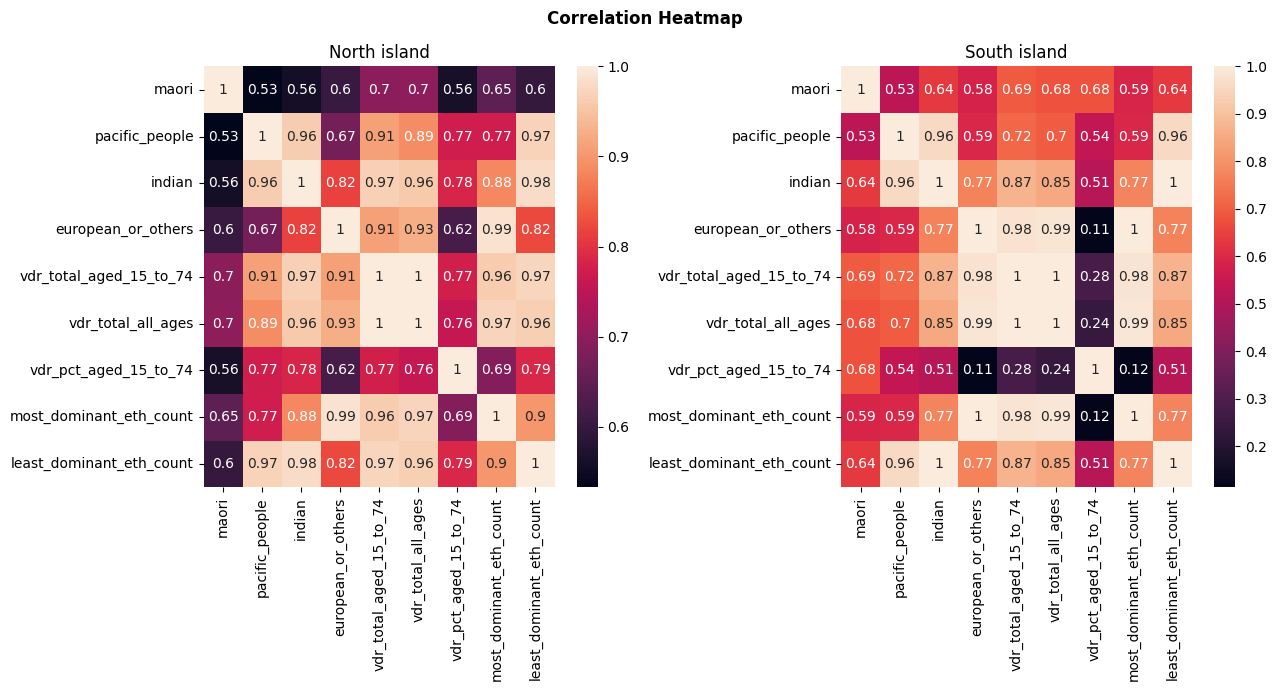

In [52]:
f,ax=plt.subplots(1,2,figsize=(13,7))
correlation_matrix_north=diabetes_vdr_nz[diabetes_vdr_nz["island"]=="North"].corr(numeric_only=True)
correlation_matrix_south=diabetes_vdr_nz[diabetes_vdr_nz["island"]=="South"].corr(numeric_only=True)
seaborn.heatmap(correlation_matrix_north,annot=True,ax=ax[0])
seaborn.heatmap(correlation_matrix_south,annot=True,ax=ax[1])
ax[0].set_title("North island")
ax[1].set_title("South island")
plt.suptitle("Correlation Heatmap",fontweight="bold")
plt.tight_layout()
plt.savefig("/kaggle/working/plots/correlation_heatmap.png")

#### 💡Insights
- The number of Indians and Pacific people with diabetes are almost near in the districts of both the North and the South island.
- The strong positive correlation between number of Indians with diabetes and the least dominant ethnic count indicates that Indians with diabetes in New Zealand are the least dominant group in the South island of New Zealand.
- A strong positive correlation exists between the diabetic Indians in the North island and the number of diabetic people aged 15 to 74 denoting that Indians with diabetes in the North island are mostly aged between 15 to 74 than the Indians with diabetes in the South island.
- A weak correlation exists between the number of diabetic people from European/other ethnic group and the percentage of diabetic people aged 15 to 74 in South island which indicates that even though European/other ethnic people with diabetes are high in number, they do not belong to the age group between 15 to 74 in South island. Larger number of European/other diabetic cases falls outside this age category of 15 to 74 and can be from North island.

#### **Distribution of number of people of different ethnicity having diabetes in New Zealand**

In [53]:
fig=px.histogram(
    diabetes_vdr_nz,
    x=["maori","indian","pacific_people","european_or_others"],
    nbins=50,
    title="Distribution of number of people of different ethnicities having diabetes in NZ",
    labels={"variable":"Ethinicity"},
    color_discrete_map=ethnicity_color_dict
)
fig.update_layout(title_x=0.5,title_font_color="black",yaxis_title="Count of people",xaxis_title="Number of people with diabetes in NZ")
fig.show()

#### **Total people with diabetes of all ages in New Zealand districts by island & most dominant ethnicity**

In [54]:
fig=px.treemap(
    data_frame=diabetes_vdr_nz,
    path=["island","district"],
    values="vdr_total_all_ages",
    color="most_dominant_eth",
    title="Total people with diabetes of all ages in New Zealand districts by island & most dominant ethnicity",
    labels={
        "vdr_total_all_ages":"Total number of people with diabetes in all ages",
        "island":"Island","district":"District",
        "most_dominant_eth":"Most dominant ethnicity"
        },
    color_discrete_map={
        "Pacific":ethnicity_color_dict["pacific_people"],
        "Maori":ethnicity_color_dict["maori"],
        "European/others":ethnicity_color_dict["european_or_others"]
        }
)
fig.update_layout(title_x=0.5,title_font_color="black")
fig.update_traces(textinfo="label+value")
fig.show()

#### 💡Insights
- Counties Manukau district have the highest number of diabetes cases comprising Pacific people as the highest ethnic group in number of people.
- Maori people are high in the number of diabetic cases in Tairawhiti, Lakes, and Northland districts.
- European/other ethnic people form the highest number of diabetic cases in all the other districts of New Zealand.

#### **Number of people with diabetes of all ages in New Zealand districts by island & least dominant ethnicity**

In [55]:
fig=px.treemap(
    data_frame=diabetes_vdr_nz,path=["island","district"],
    values="vdr_total_all_ages",
    color="least_dominant_eth",
    title="Number of people with diabetes of all ages in New Zealand districts by island & least dominant ethnicity",
    labels={
        "vdr_total_all_ages":"Total number of people with diabetes in all ages",
        "island":"Island","district":"District",
        "least_dominant_eth":"Least dominant ethnicity"
        },
    color_discrete_map={
        "Pacific":ethnicity_color_dict["pacific_people"],
        "Maori":ethnicity_color_dict["maori"],
        "European/others":ethnicity_color_dict["european_or_others"],
        "Indian":ethnicity_color_dict["indian"]
        }
    )
fig.update_layout(title_x=0.5,title_font_color="black")
fig.update_traces(textinfo="label+value")
fig.show()

#### 💡Insights
- Maori people have the lowest number of diabetic cases in Counties Manukau, Auckland and Waitemate districts among other ethnic groups in these districts.
- Pacific ethnic people have the lowest number of diabetic cases in 3 other districts namely Waikato, Bay of Plenty and Taranaki.
- Indian ethnic people form the lowest number of diabetic cases across all the districts in the South island.

#### **Number of European or other ethnicity people in NZ with diabetes by island**

In [56]:
fig=px.bar(diabetes_vdr_nz,x="district",y="european_or_others",color="island",
           text_auto=True,
           title="Number of European/other ethnicity people in NZ with diabetes by island",
           labels={"island":"Island","european_or_others":"Number of people with European or other ethnicity"},color_discrete_map=island_color_dict)
fig.update_layout(title_x=0.5,title_font_color="black",xaxis_title="District in New Zealand",yaxis_title="Number of people")
fig.update_yaxes(tickformat=",d")
fig.show()

# ⭐**Key Insights**   <a class="anchor" id="key_insights_section"></a>

🍬Ranking number of diabetes cases in New Zealand by ethnic group
  1. European/other
  2. Pacific
  3. Maori
  4. Indian
     
🇳🇿Number of people with diabetes in all ages by island
 - North - 280166 people
 - South - 97535 people
    
⬆️Top 5 districts with highest number of diabetes cases in New Zealand
  1. Counties Manukau - 67996 people
  2. Waitemata - 48578 people
  3. Auckland - 39365 people
  4. Canterbury - 34459 people
  5. Waikato - 33923 people
    
⬇️Top 5 districts with lowest number of diabetes cases in New Zealand
  1. West Coast - 2104 people
  2. Wairarapa - 3547 people
  3. Tairawhiti - 3794 people
  4. South Canterbury - 4143 people
  5. Whanganui - 5222 people
    
🧑Top 3 districts with highest number of diabetes cases among the age group 15 to 74 by ethnicity
  - Maori
   1. Waikato - 7659 people
   2. Counties Manukau - 7317 people
   3. Northland - 5502 people
  - Pacific
   1. Counties Manukau - 22334 people
   2. Auckland - 7921 people
   3. Waitemata - 6101 people
  - European/other
   1. Waitemata - 2337 people
   2. Canterbury - 19883 people
   3. Counties Manukau - 17783 people
  - Indian
   1. Counties Manukau - 9184 people
   2. Auckland - 5483 people
   3. Waitemata - 4366 people
      
🥧Top 3 districts with the highest proportion of diabetic cases in each ethnic group
 - Maori
   - Tairawhiti - 63.4%
   - Northland - 49%
   - Lakes - 46.6%
 - Pacific
    - Counties Manukau - 39.4%
    - Auckland - 25.5%
    - Capital and Coast - 18.9%
 - European/Others
    - South Canterbury - 84.2%
    - West Coast - 81.9%
    - Southern - 79.7%
 - Indian
    - Auckland - 17.6%
    - Counties Manukau - 16.2%
    - Waitemata - 11.6%